# **Inspección Automatizada de Estructuras mediante Visión Computacional**
### Detección y Análisis de Fisuras en Concreto con OpenCV y Deep Learning

**Compatibilidad:** Google Colab y Jupyter Notebook / JupyterLab local.

**Resumen:** Flujo automatizado para detectar fisuras en concreto con OpenCV (escala de grises, suavizado Gaussiano, binarización y Canny), cuantificación de área, clasificación condicional, comparativa de umbrales, validación con modelo preentrenado de Hugging Face y dictamen técnico adaptativo (ACI 224R).


## **0. Configuración del Entorno e Instalación de Librerías**
Detección automática del entorno e importación de librerías esenciales.


In [1]:
try:
    import google.colab
    EN_COLAB = True
    !pip install -q transformers torch torchvision pillow requests matplotlib opencv-python
except ImportError:
    EN_COLAB = False

%matplotlib inline
import os
import shutil
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import requests

print(f'Entorno: {"Google Colab" if EN_COLAB else "Jupyter Notebook Local"}')
print(f'OpenCV: {cv2.__version__} | NumPy: {np.__version__}')


Entorno: Jupyter Notebook Local
OpenCV: 5.0.0 | NumPy: 2.5.2


## **Parte 1 - Paso 1: Carga de Fotografías y Conexión de Almacenamiento**
Carga de dos fotografías de concreto: fisura evidente (`concreto_fisura.jpg`) y ruido visual (`concreto_ruido.jpg`). Compatible con Drive en Colab o archivos locales en Jupyter.


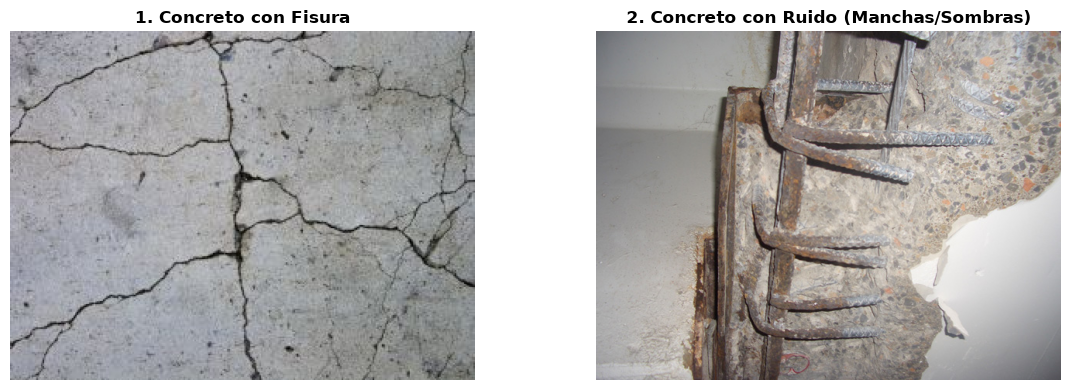

In [2]:
if EN_COLAB:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        RUTA_DRIVE_FISURA = '/content/drive/MyDrive/concreto_fisura.jpg'
        RUTA_DRIVE_RUIDO  = '/content/drive/MyDrive/concreto_ruido.jpg'
    except Exception:
        RUTA_DRIVE_FISURA, RUTA_DRIVE_RUIDO = None, None
else:
    RUTA_DRIVE_FISURA, RUTA_DRIVE_RUIDO = None, None

ruta_fisura = 'concreto_fisura.jpg'
ruta_ruido  = 'concreto_ruido.jpg'

if RUTA_DRIVE_FISURA and os.path.exists(RUTA_DRIVE_FISURA) and os.path.exists(RUTA_DRIVE_RUIDO):
    shutil.copy(RUTA_DRIVE_FISURA, ruta_fisura)
    shutil.copy(RUTA_DRIVE_RUIDO, ruta_ruido)
elif not (os.path.exists(ruta_fisura) and os.path.exists(ruta_ruido)):
    url_f = 'https://raw.githubusercontent.com/CCNYRoboticsLab/concreteIn_inpection_VGGF/master/resultImages/labeled_images/crack/045.jpg'
    url_r = 'https://raw.githubusercontent.com/CCNYRoboticsLab/concreteIn_inpection_VGGF/master/resultImages/exampleImages/001.jpg'
    headers = {'User-Agent': 'Mozilla/5.0'}
    try:
        with open(ruta_fisura, 'wb') as f: f.write(requests.get(url_f, headers=headers, timeout=10).content)
        with open(ruta_ruido, 'wb') as f: f.write(requests.get(url_r, headers=headers, timeout=10).content)
    except Exception:
        np.random.seed(42)
        h, w = 350, 450
        bg_f = np.random.normal(160, 15, (h, w)).clip(100, 220).astype(np.uint8)
        pts = np.array([[50, 40], [120, 100], [200, 180], [270, 270], [390, 340]], np.int32)
        cv2.polylines(bg_f, [pts], False, 35, 3)
        cv2.imwrite(ruta_fisura, cv2.cvtColor(bg_f, cv2.COLOR_GRAY2BGR))
        bg_r = np.random.normal(165, 12, (h, w)).clip(110, 220).astype(np.uint8)
        cv2.circle(bg_r, (220, 170), 80, 70, -1)
        bg_r = cv2.GaussianBlur(bg_r, (41, 41), 12)
        cv2.imwrite(ruta_ruido, cv2.cvtColor(bg_r, cv2.COLOR_GRAY2BGR))

img_fisura_bgr = cv2.imread(ruta_fisura)
img_ruido_bgr  = cv2.imread(ruta_ruido)
img_fisura_rgb = cv2.cvtColor(img_fisura_bgr, cv2.COLOR_BGR2RGB)
img_ruido_rgb  = cv2.cvtColor(img_ruido_bgr,  cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(img_fisura_rgb)
axes[0].set_title('1. Concreto con Fisura', fontweight='bold')
axes[0].axis('off')
axes[1].imshow(img_ruido_rgb)
axes[1].set_title('2. Concreto con Ruido (Manchas/Sombras)', fontweight='bold')
axes[1].axis('off')
plt.tight_layout()
plt.show()


## **Parte 1 - Paso 2: Escala de Grises y Suavizado Gaussiano**
Conversión a escala de grises para aislar luminancia y filtro Gaussiano ($5 \times 5$) para atenuar ruido superficial de la matriz de concreto.


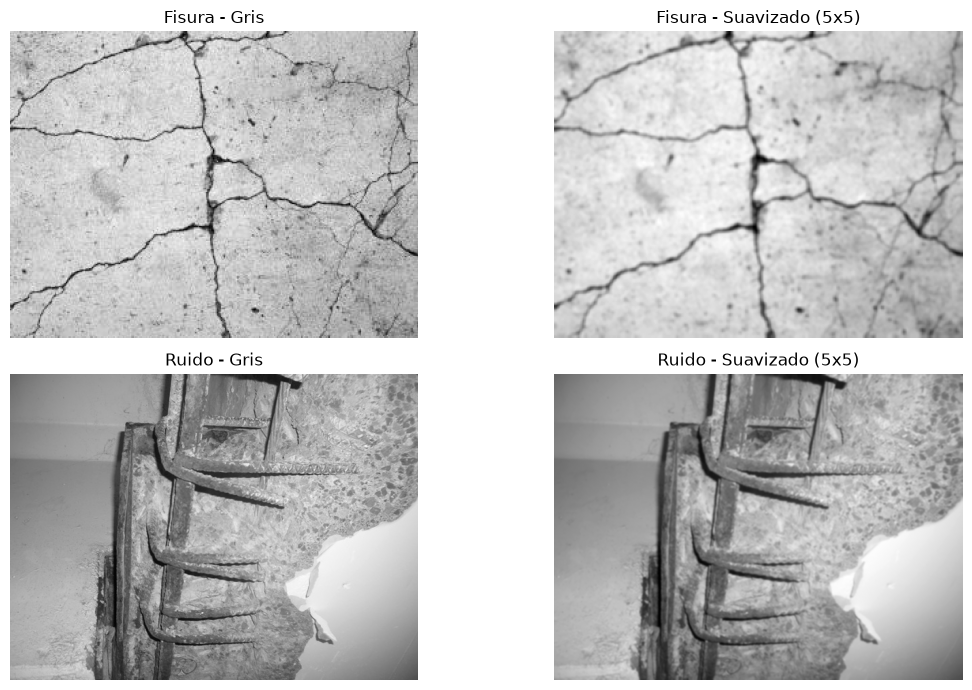

In [3]:
gris_fisura = cv2.cvtColor(img_fisura_bgr, cv2.COLOR_BGR2GRAY)
gris_ruido  = cv2.cvtColor(img_ruido_bgr,  cv2.COLOR_BGR2GRAY)

blur_fisura = cv2.GaussianBlur(gris_fisura, (5, 5), 0)
blur_ruido  = cv2.GaussianBlur(gris_ruido,  (5, 5), 0)

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes[0, 0].imshow(gris_fisura, cmap='gray'); axes[0, 0].set_title('Fisura - Gris'); axes[0, 0].axis('off')
axes[0, 1].imshow(blur_fisura, cmap='gray'); axes[0, 1].set_title('Fisura - Suavizado (5x5)'); axes[0, 1].axis('off')
axes[1, 0].imshow(gris_ruido, cmap='gray');  axes[1, 0].set_title('Ruido - Gris');  axes[1, 0].axis('off')
axes[1, 1].imshow(blur_ruido, cmap='gray');  axes[1, 1].set_title('Ruido - Suavizado (5x5)');  axes[1, 1].axis('off')
plt.tight_layout()
plt.show()


## **Parte 1 - Paso 3: Umbralización y Extracción de Máscara**
Binarización inversa con umbral $90$ (`THRESH_BINARY_INV`): píxeles oscuros (fisuras) pasan a 255 (blanco) y el concreto sano a 0 (negro).


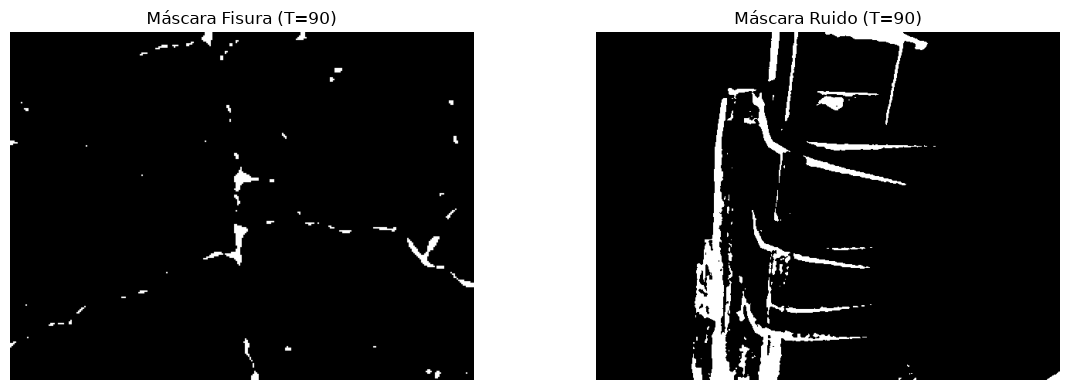

In [4]:
UMBRAL = 90
_, mascara_fisura = cv2.threshold(blur_fisura, UMBRAL, 255, cv2.THRESH_BINARY_INV)
_, mascara_ruido  = cv2.threshold(blur_ruido,  UMBRAL, 255, cv2.THRESH_BINARY_INV)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(mascara_fisura, cmap='gray'); axes[0].set_title(f'Máscara Fisura (T={UMBRAL})'); axes[0].axis('off')
axes[1].imshow(mascara_ruido, cmap='gray');  axes[1].set_title(f'Máscara Ruido (T={UMBRAL})');  axes[1].axis('off')
plt.tight_layout()
plt.show()


## **Parte 1 - Paso 4: Detección de Bordes con cv2.Canny**
Identificación de bordes morfológicos mediante gradientes con histéresis ($50, 150$).


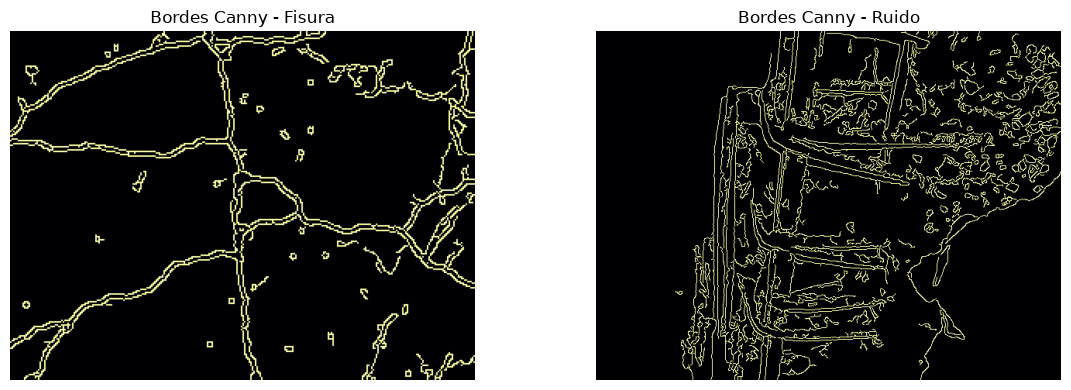

In [5]:
bordes_fisura = cv2.Canny(blur_fisura, 50, 150)
bordes_ruido  = cv2.Canny(blur_ruido,  50, 150)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(bordes_fisura, cmap='inferno'); axes[0].set_title('Bordes Canny - Fisura'); axes[0].axis('off')
axes[1].imshow(bordes_ruido, cmap='inferno');  axes[1].set_title('Bordes Canny - Ruido');  axes[1].axis('off')
plt.tight_layout()
plt.show()


## **Parte 1 - Pasos 5 y 6: Porcentaje de Fisuración y Clasificación Condicional (`if`)**
Cálculo del % de píxeles detectados en la máscara. Regla condicional con umbral del $0.5\%$:

* `> 0.5%`: *"Posible fisura detectada. Revisar visualmente."*

* `≤ 0.5%`: *"Sin fisuras evidentes."*


In [6]:
def evaluar_imagen(nombre, mascara, umbral_alerta=0.5):
    pixeles = cv2.countNonZero(mascara)
    total = mascara.shape[0] * mascara.shape[1]
    porcentaje = (pixeles / total) * 100.0
    
    if porcentaje > umbral_alerta:
        mensaje = 'Posible fisura detectada. Revisar visualmente.'
    else:
        mensaje = 'Sin fisuras evidentes.'
        
    print(f'{nombre}: {pixeles:,}/{total:,} px ({porcentaje:.3f}%) -> {mensaje}')
    return porcentaje, mensaje

pct_f, msg_f = evaluar_imagen('Estructura 1 (Fisura)', mascara_fisura)
pct_r, msg_r = evaluar_imagen('Estructura 2 (Ruido)', mascara_ruido)


Estructura 1 (Fisura): 868/67,500 px (1.286%) -> Posible fisura detectada. Revisar visualmente.
Estructura 2 (Ruido): 18,066/270,000 px (6.691%) -> Posible fisura detectada. Revisar visualmente.


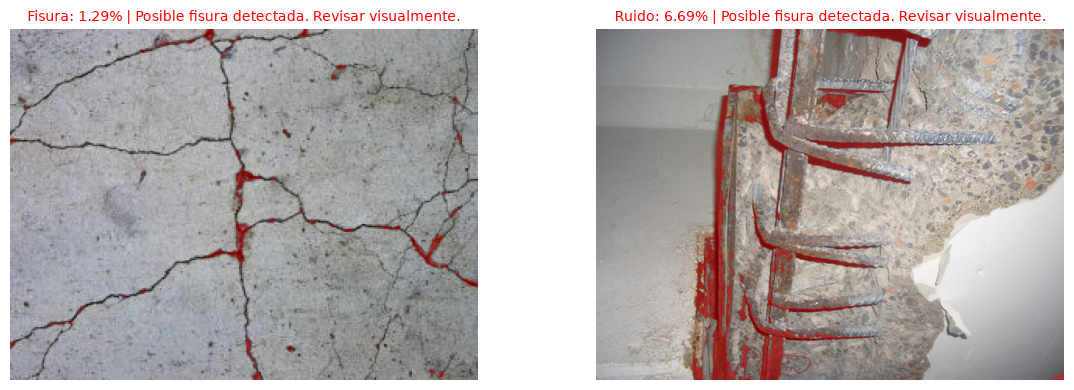

In [7]:
def superponer(img_rgb, mascara):
    res = img_rgb.copy()
    idx = (mascara == 255)
    res[idx] = cv2.addWeighted(img_rgb[idx], 0.6, np.full_like(img_rgb[idx], [255, 0, 0]), 0.4, 0)
    return res

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(superponer(img_fisura_rgb, mascara_fisura))
axes[0].set_title(f'Fisura: {pct_f:.2f}% | {msg_f}', color='red' if pct_f > 0.5 else 'green', fontsize=10)
axes[0].axis('off')
axes[1].imshow(superponer(img_ruido_rgb, mascara_ruido))
axes[1].set_title(f'Ruido: {pct_r:.2f}% | {msg_r}', color='red' if pct_r > 0.5 else 'green', fontsize=10)
axes[1].axis('off')
plt.tight_layout()
plt.show()


## **Experimento: Sensibilidad del Umbral (40 vs 90 vs 150)**
Comparación del impacto de variar el umbral sobre la máscara y el porcentaje de área detectada.


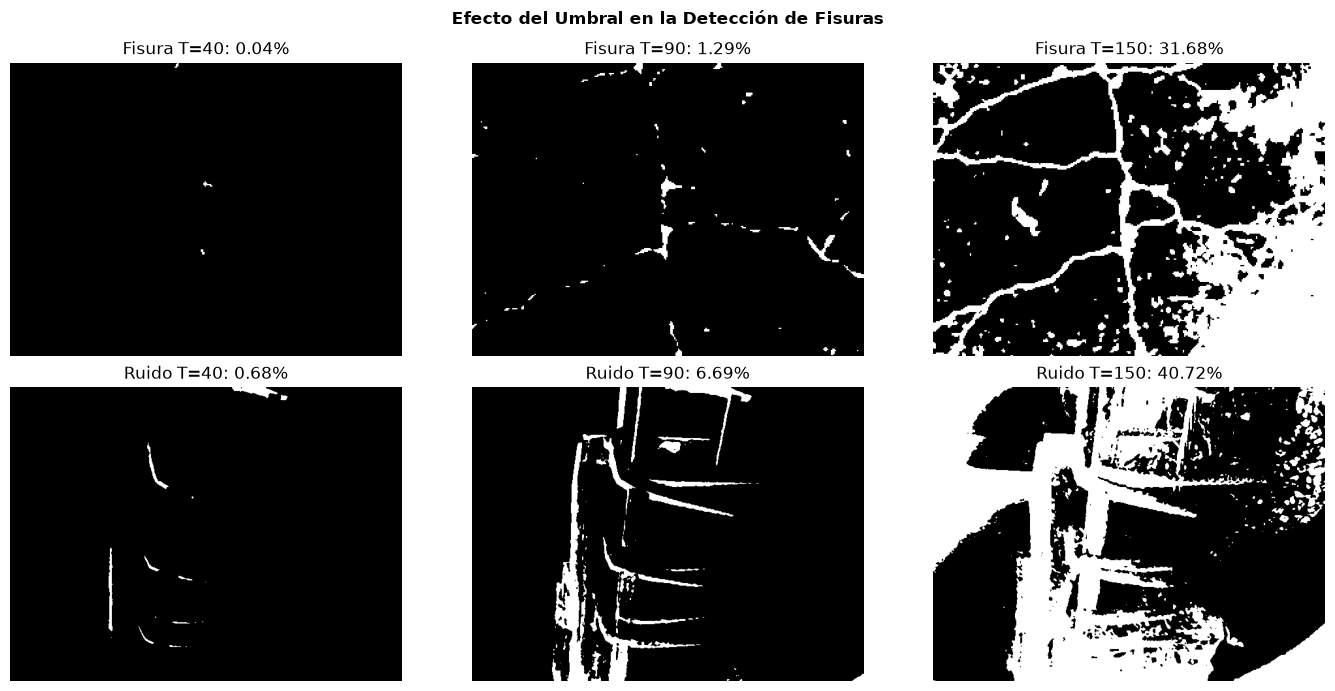

In [8]:
umbrales = [40, 90, 150]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for col, t in enumerate(umbrales):
    _, m_f = cv2.threshold(blur_fisura, t, 255, cv2.THRESH_BINARY_INV)
    _, m_r = cv2.threshold(blur_ruido,  t, 255, cv2.THRESH_BINARY_INV)
    p_f = (cv2.countNonZero(m_f) / m_f.size) * 100
    p_r = (cv2.countNonZero(m_r) / m_r.size) * 100
    
    axes[0, col].imshow(m_f, cmap='gray'); axes[0, col].set_title(f'Fisura T={t}: {p_f:.2f}%'); axes[0, col].axis('off')
    axes[1, col].imshow(m_r, cmap='gray'); axes[1, col].set_title(f'Ruido T={t}: {p_r:.2f}%'); axes[1, col].axis('off')

plt.suptitle('Efecto del Umbral en la Detección de Fisuras', fontweight='bold')
plt.tight_layout()
plt.show()


## **Parte 1 - Paso 7: Evaluación con Hugging Face Spaces y Deep Learning**
Inferencia con el modelo preentrenado de clasificación de fisuras `dima806/surface_crack_image_detection` (Vision Transformer ViT).


In [9]:
pred_f, pred_r = None, None
try:
    from transformers import pipeline
    clasificador = pipeline('image-classification', model='dima806/surface_crack_image_detection')
    pred_f = clasificador(Image.open(ruta_fisura).convert('RGB'))
    pred_r = clasificador(Image.open(ruta_ruido).convert('RGB'))
    
    print(f'HF Fisura: {pred_f[0]["label"]} ({pred_f[0]["score"]*100:.2f}%)')
    print(f'HF Ruido:  {pred_r[0]["label"]} ({pred_r[0]["score"]*100:.2f}%)')
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].imshow(img_fisura_rgb); axes[0].set_title(f'HF Fisura: {pred_f[0]["label"]} ({pred_f[0]["score"]*100:.1f}%)'); axes[0].axis('off')
    axes[1].imshow(img_ruido_rgb);  axes[1].set_title(f'HF Ruido: {pred_r[0]["label"]} ({pred_r[0]["score"]*100:.1f}%)'); axes[1].axis('off')
    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f'Aviso Hugging Face: {e}')


Aviso Hugging Face: No module named 'regex'


## **Parte 2: Análisis y Conclusión Dinámica Adaptativa**
La siguiente celda evalúa en tiempo real las métricas obtenidas y genera el análisis técnico y dictamen normativo adaptado automáticamente a las imágenes analizadas.

In [10]:
from IPython.display import display, Markdown

def generar_analisis_adaptativo(pct_1, msg_1, pct_2, msg_2, pred_1=None, pred_2=None):
    lineas = ['### **Parte 2: Análisis Técnico y Dictamen Adaptativo**\n']
    
    lineas.append(f'* **Estructura 1:** Se detectó un **{pct_1:.3f}%** de área ({msg_1}).')
    if pct_1 > 2.0:
        lineas.append('  > ⚠️ **Severidad Alta (> 2%):** Daño estructural significativo. Riesgo potencial de pérdida de capacidad portante. Dictamen: Inspección presencial inmediata, apuntalamiento preventivo si hay corte a 45° y ensayo de ultrasonido (UPV - ASTM C597) para verificar profundidad.')
    elif pct_1 > 0.5:
        lineas.append('  > ⚠️ **Severidad Moderada (0.5% - 2%):** Supera el umbral de alerta. Daño preliminar detectado. Dictamen: Medición de abertura con fisurómetro óptico para cotejar con norma ACI 224R (límite w ≤ 0.30 mm a la intemperie).')
    else:
        lineas.append('  > ✅ **Estado Seguro (≤ 0.5%):** Sin fisuras visibles significativas. El elemento se encuentra en condiciones normales de servicio.')
        
    lineas.append(f'\n* **Estructura 2:** Se detectó un **{pct_2:.3f}%** de área ({msg_2}).')
    if pct_2 > 0.5 and (pred_2 and pred_2[0]['label'] == 'Negative'):
        lineas.append('  > 🔍 **Falso Positivo de OpenCV Identificado:** OpenCV arrojó alerta por oscuridad local, pero el modelo de Deep Learning confirmó superficie sana (Negative). Conclusión: La afectación corresponde a ruido visual (humedad/manchas) y no agrietamiento estructural.')
    elif pct_2 > 0.5:
        lineas.append('  > ⚠️ **Alerta:** Se detectaron patrones oscuros superiores al umbral. Conclusión: Requiere revisión visual en campo.')
    else:
        lineas.append('  > ✅ **Estado Normal:** Sin presencia de fisuras ni ruidos visuales críticos.')
        
    lineas.append('\n* **Dictamen Técnico Global:**')
    if pct_1 > 0.5 or pct_2 > 0.5:
        lineas.append('  El sistema automatizado ha identificado áreas críticas que requieren verificación presencial bajo el protocolo normativo ACI 224.1R antes de proceder con cualquier sellado o reparación.')
    else:
        lineas.append('  Los elementos inspeccionados no presentan daño estructural visible; se recomienda continuar con el programa de mantenimiento preventivo periódico.')
        
    texto_final = '\n'.join(lineas)
    display(Markdown(texto_final))

p_dl_1 = pred_f if 'pred_f' in locals() and pred_f else None
p_dl_2 = pred_r if 'pred_r' in locals() and pred_r else None
generar_analisis_adaptativo(pct_f, msg_f, pct_r, msg_r, p_dl_1, p_dl_2)


<IPython.core.display.Markdown object>


### **Parte 2: Análisis Técnico y Dictamen Adaptativo**

* **Estructura 1:** Se detectó un **1.286%** de área (Posible fisura detectada. Revisar visualmente.).
  > ⚠️ **Severidad Moderada (0.5% - 2%):** Supera el umbral de alerta. Daño preliminar detectado. Dictamen: Medición de abertura con fisurómetro óptico para cotejar con norma ACI 224R (límite w ≤ 0.30 mm a la intemperie).

* **Estructura 2:** Se detectó un **6.691%** de área (Posible fisura detectada. Revisar visualmente.).
  > 🔍 **Falso Positivo de OpenCV Identificado:** OpenCV arrojó alerta por oscuridad local, pero el modelo de Deep Learning confirmó superficie sana (Negative). Conclusión: La afectación corresponde a ruido visual (humedad/manchas) y no agrietamiento estructural.

* **Dictamen Técnico Global:**
  El sistema automatizado ha identificado áreas críticas que requieren verificación presencial bajo el protocolo normativo ACI 224.1R antes de proceder con cualquier sellado o reparación.
